# 02 · Hierarchical clustering of the SOM (SM7, SM8, SM9, Table SM3)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**
1. Loads the trained 8 × 9 SOM and assigns each sample to its best-matching unit (BMU).
2. Chooses the number of clusters **K** from the within-cluster sum of squares (elbow) and the silhouette score, computed on the 72 codebook vectors for K = 2 to 14 (Figure SM8).
3. Applies **hierarchical clustering (average linkage, Euclidean distance) with K = 4** to the codebook vectors (Haselbeck et al., 2019); each sample inherits the cluster of its BMU.
4. Draws the major-ion box plots per cluster (Figure SM9) and the component planes with cluster boundaries (Figure SM7).
5. Exports the dataset with the cluster of each sample.
6. Compares the SOM-based facies with a direct hierarchical clustering of the 406 samples (Ward linkage, the dendrogram of Figure 7): contingency table and adjusted Rand index (Table SM3).

| | |
|---|---|
| **Inputs** | `outputs/intermediate/data_preprocessed_full.xlsx`, `som_model_final.p` (from `01_PCA_SOM_training.ipynb`) |
| **Figures** | `SM07_SOM_component_planes_K4_boundaries`, `SM08_WSS_Silhouette_K_selection`, `SM09_boxplots_per_cluster_mgL` |
| **Outputs** | `outputs/intermediate/data_final_with_clusters.xlsx` (406 samples, BMU and Cluster columns); `outputs/tables/som_vs_direct_hca_agreement.xlsx` (Table SM3) |
| **Next notebook** | `03_SOM_figures.ipynb` (Figures 6, 7, 8, 9) |

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Core ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import sklearn, scipy, minisom
import pickle, warnings
from pathlib import Path

# ── SOM ───────────────────────────────────────────────────────────────
from minisom import MiniSom

# ── Clustering & Validation ──────────────────────────────────────────
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

# ── Plotting helpers ─────────────────────────────────────────────────
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ── Settings ─────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

SEED = 42
np.random.seed(SEED)

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_FIGURES  = ROOT / "outputs" / "figures"
DIR_TABLES   = ROOT / "outputs" / "tables"
for d in (DIR_FIGURES, DIR_TABLES):
    d.mkdir(parents=True, exist_ok=True)

print("Package versions:")
for name, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns),
                  ("scikit-learn", sklearn), ("scipy", scipy), ("minisom", minisom)]:
    print(f"  {name:14s} {getattr(mod, '__version__', 'installed')}")
print(f"\nRandom seed : {SEED}")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Package versions:
  numpy          1.26.4
  pandas         2.2.3
  matplotlib     3.7.2
  seaborn        0.12.2
  scikit-learn   1.9.0
  scipy          1.17.1
  minisom        installed

Random seed : 42


### <font color='orange'> **2) Load the data and the trained SOM** </font>

In [2]:
# ── Load preprocessed data ───────────────────────────────────────────
df = pd.read_excel(DIR_INTERMED / "data_preprocessed_full.xlsx")

# Column groups (as in the previous notebooks)
MAJOR_IONS  = ["Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
               "HCO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)"]
IONS_MEQ    = [c.replace("(mg/L)", "(meq/L)") for c in MAJOR_IONS]
IONS_REL    = [c.replace("(mg/L)", "(%)") for c in MAJOR_IONS]
IONS_SCALED = [c.replace("(mg/L)", "(scaled)") for c in MAJOR_IONS]
ION_LABELS  = [c.replace(" (mg/L)", "") for c in MAJOR_IONS]

# SOM input matrix
data_som = df[IONS_SCALED].values

# ── Load trained SOM model ──────────────────────────────────────────
with open(DIR_INTERMED / "som_model_final.p", "rb") as f:
    som = pickle.load(f)

# Grid dimensions
ROWS, COLS = som.get_weights().shape[0], som.get_weights().shape[1]
weights = som.get_weights()  # (ROWS, COLS, 7)

print(f"Dataset      : {df.shape[0]} samples × {df.shape[1]} columns")
print(f"SOM input    : {data_som.shape}")
print(f"SOM grid     : {ROWS} × {COLS} = {ROWS*COLS} neurons (hexagonal)")
print(f"Codebook     : {weights.shape}")

# ── Compute BMU for each sample ─────────────────────────────────────
bmu_list = [som.winner(x) for x in data_som]
df["BMU_row"] = [b[0] for b in bmu_list]
df["BMU_col"] = [b[1] for b in bmu_list]

print(f"\nBMU assigned : {len(bmu_list)} samples")

Dataset      : 406 samples × 35 columns
SOM input    : (406, 7)
SOM grid     : 8 × 9 = 72 neurons (hexagonal)
Codebook     : (8, 9, 7)

BMU assigned : 406 samples


### <font color='orange'> **3) Number of clusters (K)** </font>

> Clustering is performed on the **codebook vectors** (72 neurons × 7 features), not on the samples (Haselbeck et al., 2019). Two criteria are combined:
> - **WSS elbow:** within-cluster sum of squares for K = 2 to 14; the elbow marks diminishing returns.
> - **Silhouette score:** mean silhouette per K; higher means better separated clusters.

In [3]:
# ── 3.1  Flatten codebook vectors for clustering ────────────────────

# Reshape from (ROWS, COLS, 7) to (72, 7)
codebook = weights.reshape(-1, weights.shape[2])
print(f"Codebook vectors: {codebook.shape} (neurons × features)")

# ── Compute WSS and Silhouette for K = 2 to 14 ─────────────────────
K_range = range(2, 15)
wss_list = []
sil_list = []

for k in K_range:
    # Hierarchical clustering with average linkage (Haselbeck et al., 2019)
    Z = linkage(codebook, method="average", metric="euclidean")
    labels = fcluster(Z, t=k, criterion="maxclust")

    # WSS: sum of squared distances within each cluster
    wss = 0
    for c in range(1, k + 1):
        cluster_points = codebook[labels == c]
        centroid = cluster_points.mean(axis=0)
        wss += np.sum((cluster_points - centroid) ** 2)
    wss_list.append(wss)

    # Silhouette score (mean across all neurons)
    if k < len(codebook):  # silhouette needs k < n
        sil = silhouette_score(codebook, labels, metric="euclidean")
    else:
        sil = np.nan
    sil_list.append(sil)

# Store results
df_k = pd.DataFrame({
    "K": list(K_range),
    "WSS": [round(w, 2) for w in wss_list],
    "Silhouette": [round(s, 4) if not np.isnan(s) else np.nan for s in sil_list],
})

print("\n── K selection metrics ─────────────────────────────────────\n")
display(df_k)

Codebook vectors: (72, 7) (neurons × features)

── K selection metrics ─────────────────────────────────────



,K,WSS,Silhouette
0,2,150.54,0.3729
1,3,79.96,0.4328
2,4,46.74,0.4715
3,5,42.80,0.4329
4,6,38.11,0.4120
5,7,33.06,0.3527
6,8,31.92,0.3440
7,9,28.81,0.2987
8,10,24.27,0.2944
9,11,18.22,0.3111


#### **3.2 Figure SM8: WSS elbow and silhouette**

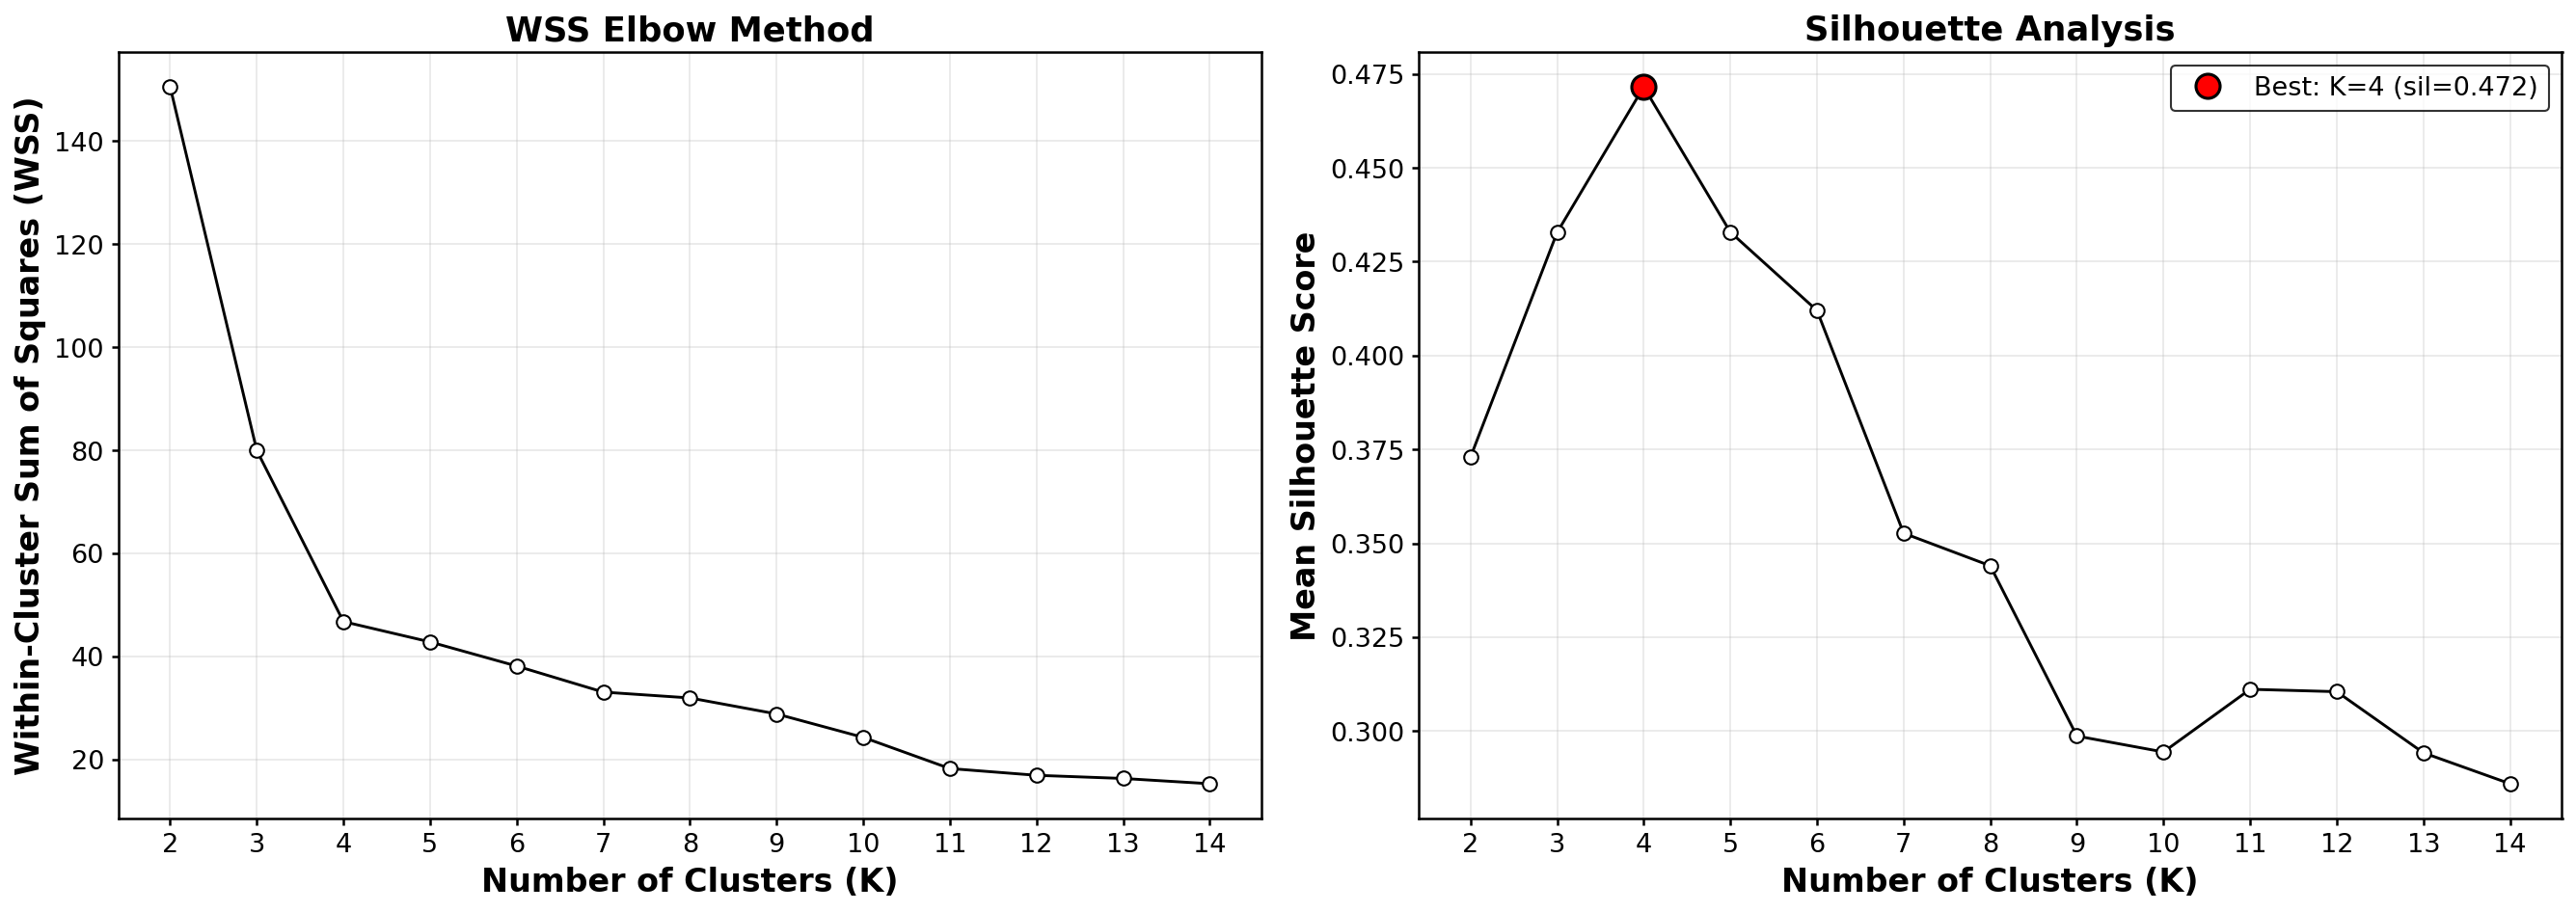


── Best K by silhouette: 4
   The WSS elbow (Figure SM8a) supports the same K.


In [4]:
# ── 3.2  WSS Elbow plot & Silhouette plot (side by side) ─────────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))

# ── (a) WSS Elbow ───────────────────────────────────────────────────
ax1.plot(list(K_range), wss_list, "o-", color="black", linewidth=1.4,
         markersize=7, markerfacecolor="white", markeredgecolor="black")
ax1.set_xlabel("Number of Clusters (K)", fontsize=16, fontweight="bold")
ax1.set_ylabel("Within-Cluster Sum of Squares (WSS)", fontsize=16, fontweight="bold")
ax1.set_title("WSS Elbow Method", fontsize=17, fontweight="bold")
ax1.set_xticks(list(K_range))
ax1.tick_params(axis="both", labelsize=13)

for spine in ax1.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
ax1.tick_params(axis="both", colors="black", width=1.2)

# ── (b) Silhouette ──────────────────────────────────────────────────
ax2.plot(list(K_range), sil_list, "o-", color="black", linewidth=1.4,
         markersize=7, markerfacecolor="white", markeredgecolor="black")

# Highlight best silhouette
best_k_sil = list(K_range)[np.nanargmax(sil_list)]
best_sil = np.nanmax(sil_list)
ax2.plot(best_k_sil, best_sil, "o", color="red", markersize=12,
         markeredgecolor="black", markeredgewidth=1.5, zorder=5,
         label=f"Best: K={best_k_sil} (sil={best_sil:.3f})")

ax2.set_xlabel("Number of Clusters (K)", fontsize=16, fontweight="bold")
ax2.set_ylabel("Mean Silhouette Score", fontsize=16, fontweight="bold")
ax2.set_title("Silhouette Analysis", fontsize=17, fontweight="bold")
ax2.set_xticks(list(K_range))
ax2.tick_params(axis="both", labelsize=13)
ax2.legend(fontsize=13, loc="best", edgecolor="black")

for spine in ax2.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
ax2.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM08_WSS_Silhouette_K_selection.png", dpi=300)
plt.show()

print(f"\n── Best K by silhouette: {best_k_sil}")
print(f"   The WSS elbow (Figure SM8a) supports the same K.")

### <font color='orange'> **4) Hierarchical clustering (K = 4)** </font>

> Average linkage on the 72 codebook vectors (Haselbeck et al., 2019). K = 4: best silhouette score (0.472) and WSS elbow. Each neuron gets a cluster label, and each sample inherits the cluster of its BMU.

In [5]:
# ── 4.1  Apply hierarchical clustering on codebook vectors ───────────

K_FINAL = 4

# Hierarchical clustering - average linkage (Haselbeck et al., 2019)
Z = linkage(codebook, method="average", metric="euclidean")
neuron_labels = fcluster(Z, t=K_FINAL, criterion="maxclust")

# Reshape neuron labels to grid shape (ROWS × COLS)
neuron_cluster_map = neuron_labels.reshape(ROWS, COLS)

# ── Assign each sample to the cluster of its BMU ────────────────────
df["Cluster"] = [neuron_cluster_map[r, c] for r, c in zip(df["BMU_row"], df["BMU_col"])]

# ── Summary ─────────────────────────────────────────────────────────
print(f"── Clustering Complete (K={K_FINAL}, average linkage) ─────────────\n")
print(f"Neurons per cluster:")
for k in range(1, K_FINAL + 1):
    n_neurons = (neuron_labels == k).sum()
    n_samples = (df["Cluster"] == k).sum()
    print(f"  Cluster {k}: {n_neurons:3d} neurons, {n_samples:3d} samples")

print(f"\nTotal: {len(neuron_labels)} neurons, {len(df)} samples")

# ── Silhouette score for this K ─────────────────────────────────────
sil_k = silhouette_score(codebook, neuron_labels, metric="euclidean")
print(f"\nMean silhouette score (neurons): {sil_k:.4f}")

── Clustering Complete (K=4, average linkage) ─────────────

Neurons per cluster:
  Cluster 1:   6 neurons,  41 samples
  Cluster 2:  25 neurons, 128 samples
  Cluster 3:  26 neurons, 162 samples
  Cluster 4:  15 neurons,  75 samples

Total: 72 neurons, 406 samples

Mean silhouette score (neurons): 0.4715


### <font color='orange'> **5) Figure SM9: major-ion box plots per cluster (mg/L, log scale)** </font>

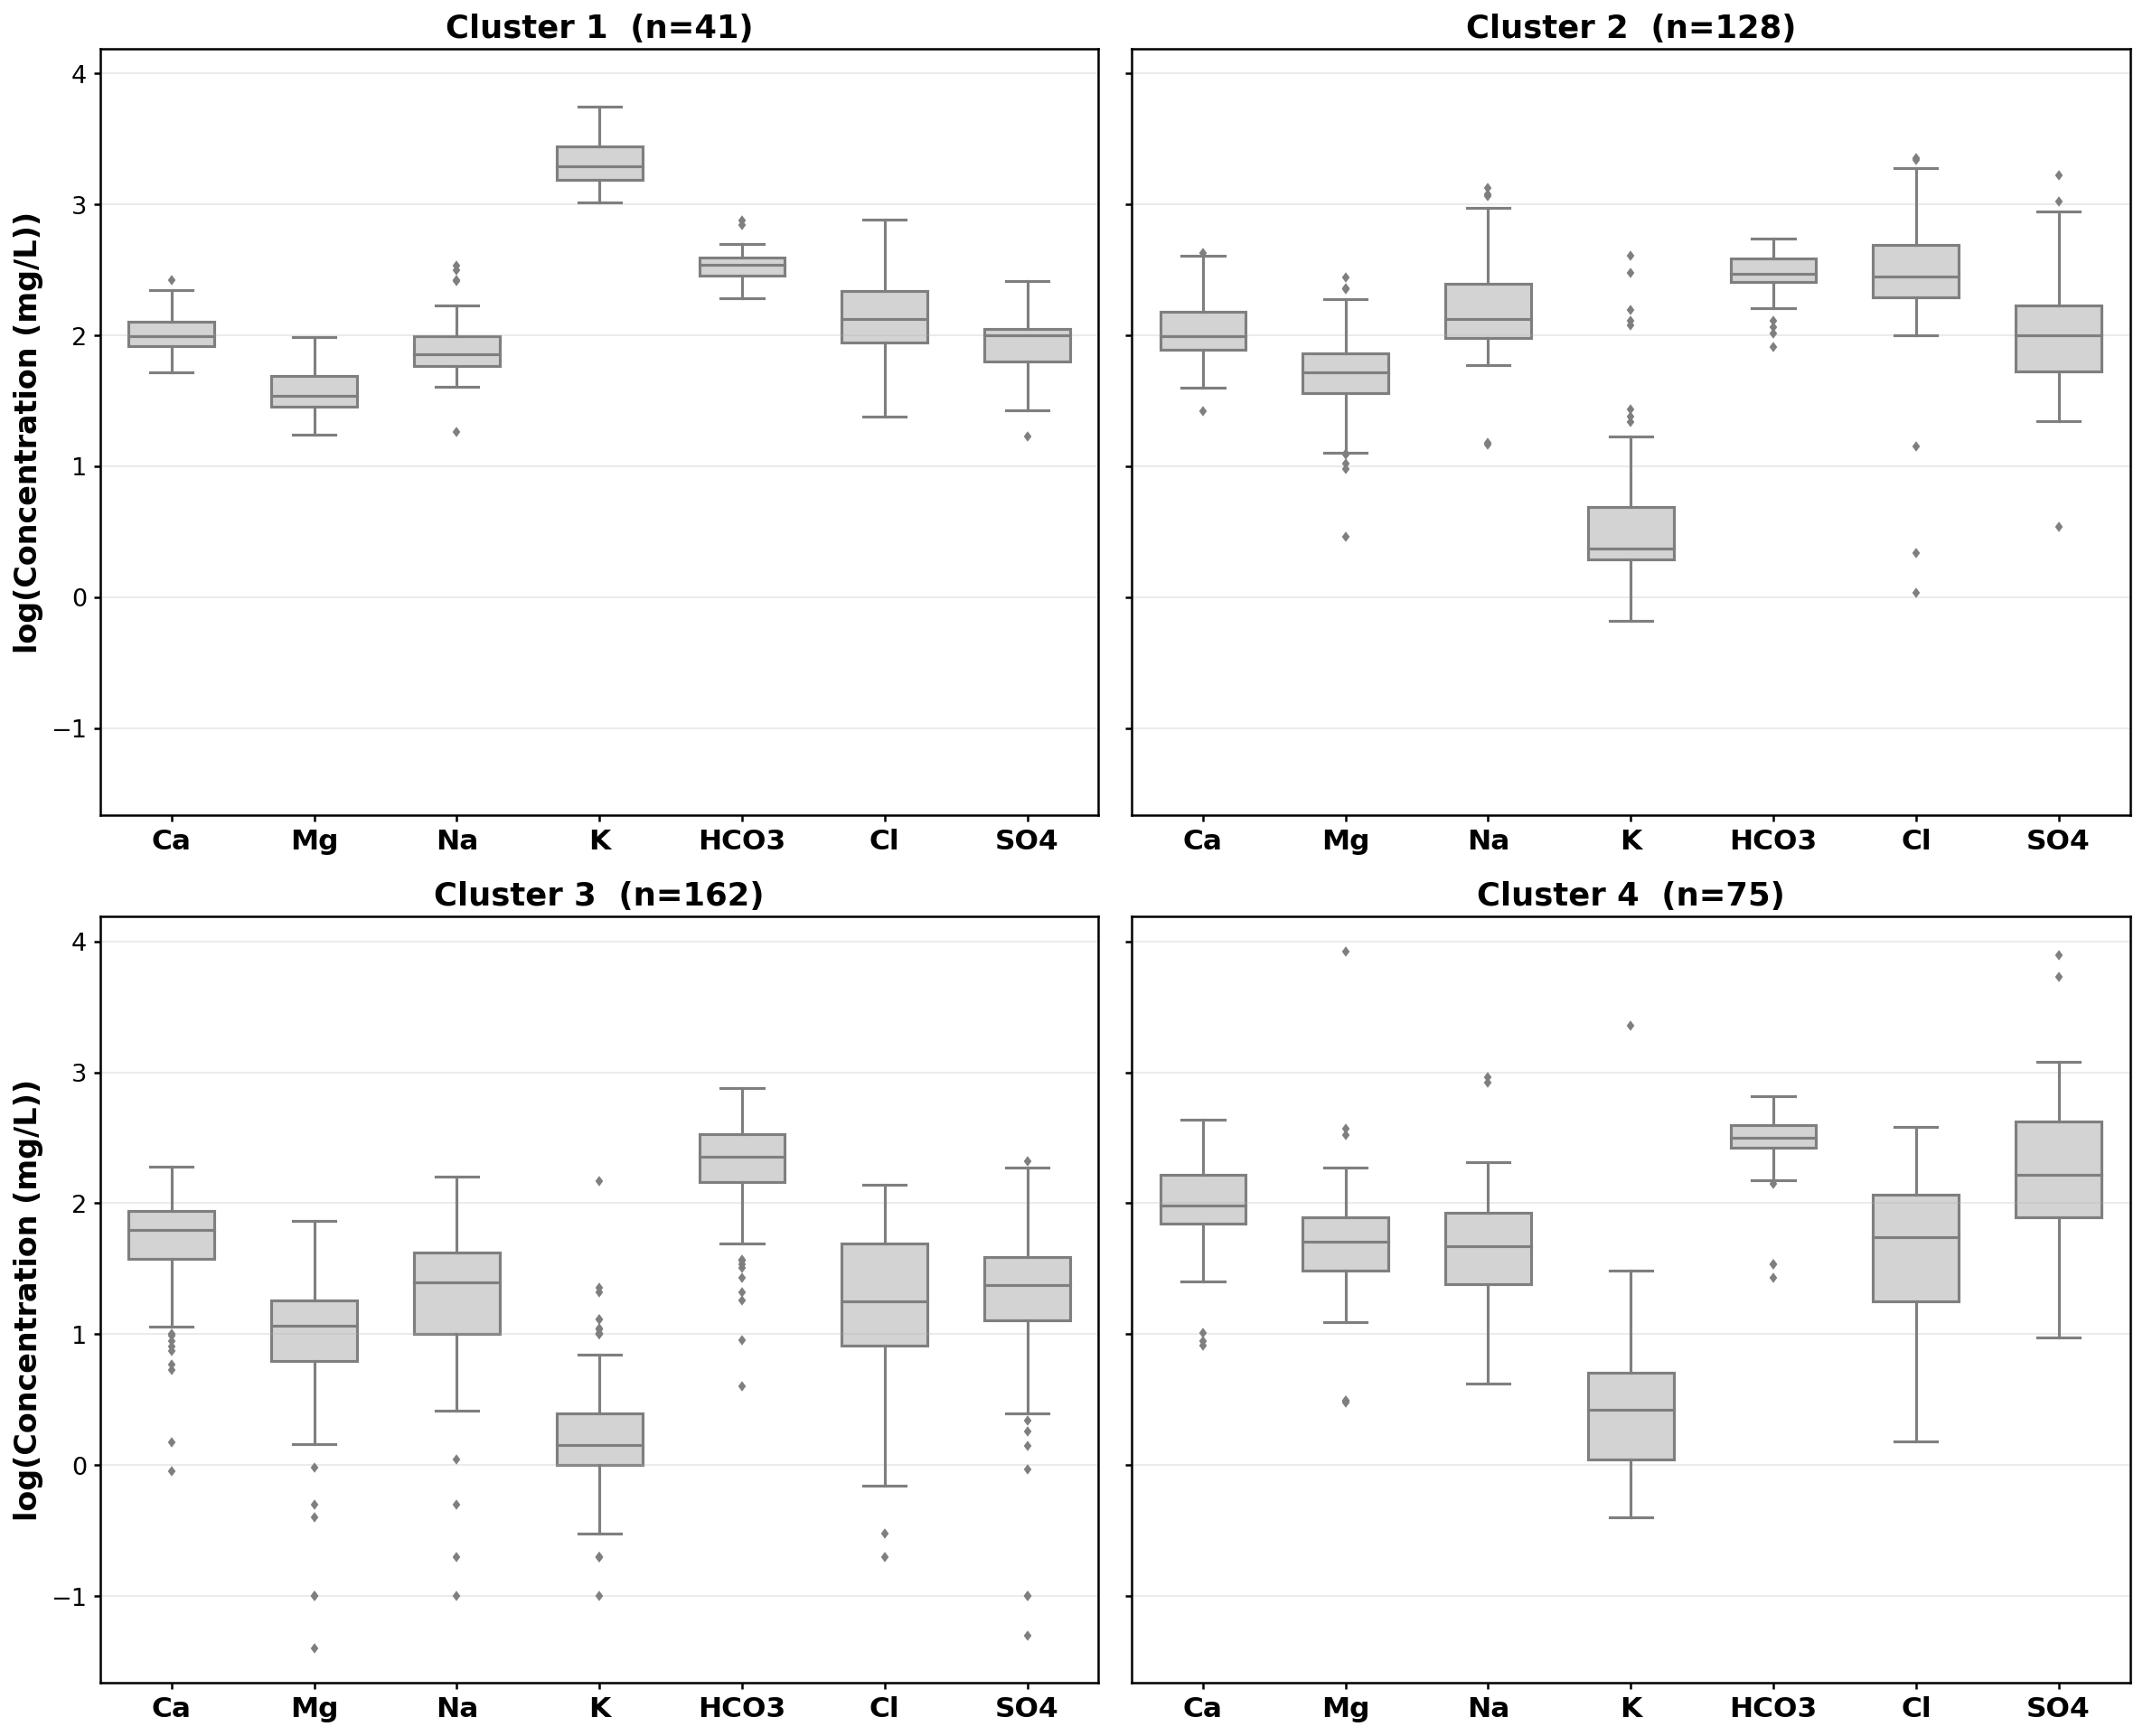

In [6]:
# ── 6.1  Boxplots per cluster - mg/L log scale (2×2 layout) ─────────

fig, axes = plt.subplots(2, 2, figsize=(16, 13), sharey=True)

for k in range(1, K_FINAL + 1):
    row = (k - 1) // 2
    col = (k - 1) % 2
    ax = axes[row, col]

    df_k = df[df["Cluster"] == k][MAJOR_IONS].copy()
    df_k.columns = ION_LABELS

    # Log10 transform
    df_log_k = df_k.replace(0, np.nan)
    df_log_k = np.log10(df_log_k)

    # Long format
    df_long_k = df_log_k.melt(var_name="Ion", value_name="log_Concentration")

    sns.boxplot(
        data=df_long_k,
        x="Ion",
        y="log_Concentration",
        color="lightgray",
        width=0.6,
        fliersize=3,
        ax=ax,
    )

    ax.set_title(f"Cluster {k}  (n={len(df_k)})", fontsize=17, fontweight="bold")
    ax.set_xlabel("")
    if col == 0:
        ax.set_ylabel("log(Concentration (mg/L))", fontsize=16, fontweight="bold")
    else:
        ax.set_ylabel("")

    # Bigger bold ion labels on x-axis
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=15, fontweight="bold")
    ax.tick_params(axis="y", labelsize=13)

    # Black axes
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
    ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM09_boxplots_per_cluster_mgL.png", dpi=600)
plt.show()

### <font color='orange'> **6) Figure SM7: component planes with cluster boundaries** </font>

> The seven component planes of the SOM, with the cluster boundaries (K = 4) drawn as thick black lines on the shared edges of the hexagons (Haselbeck et al., 2019).

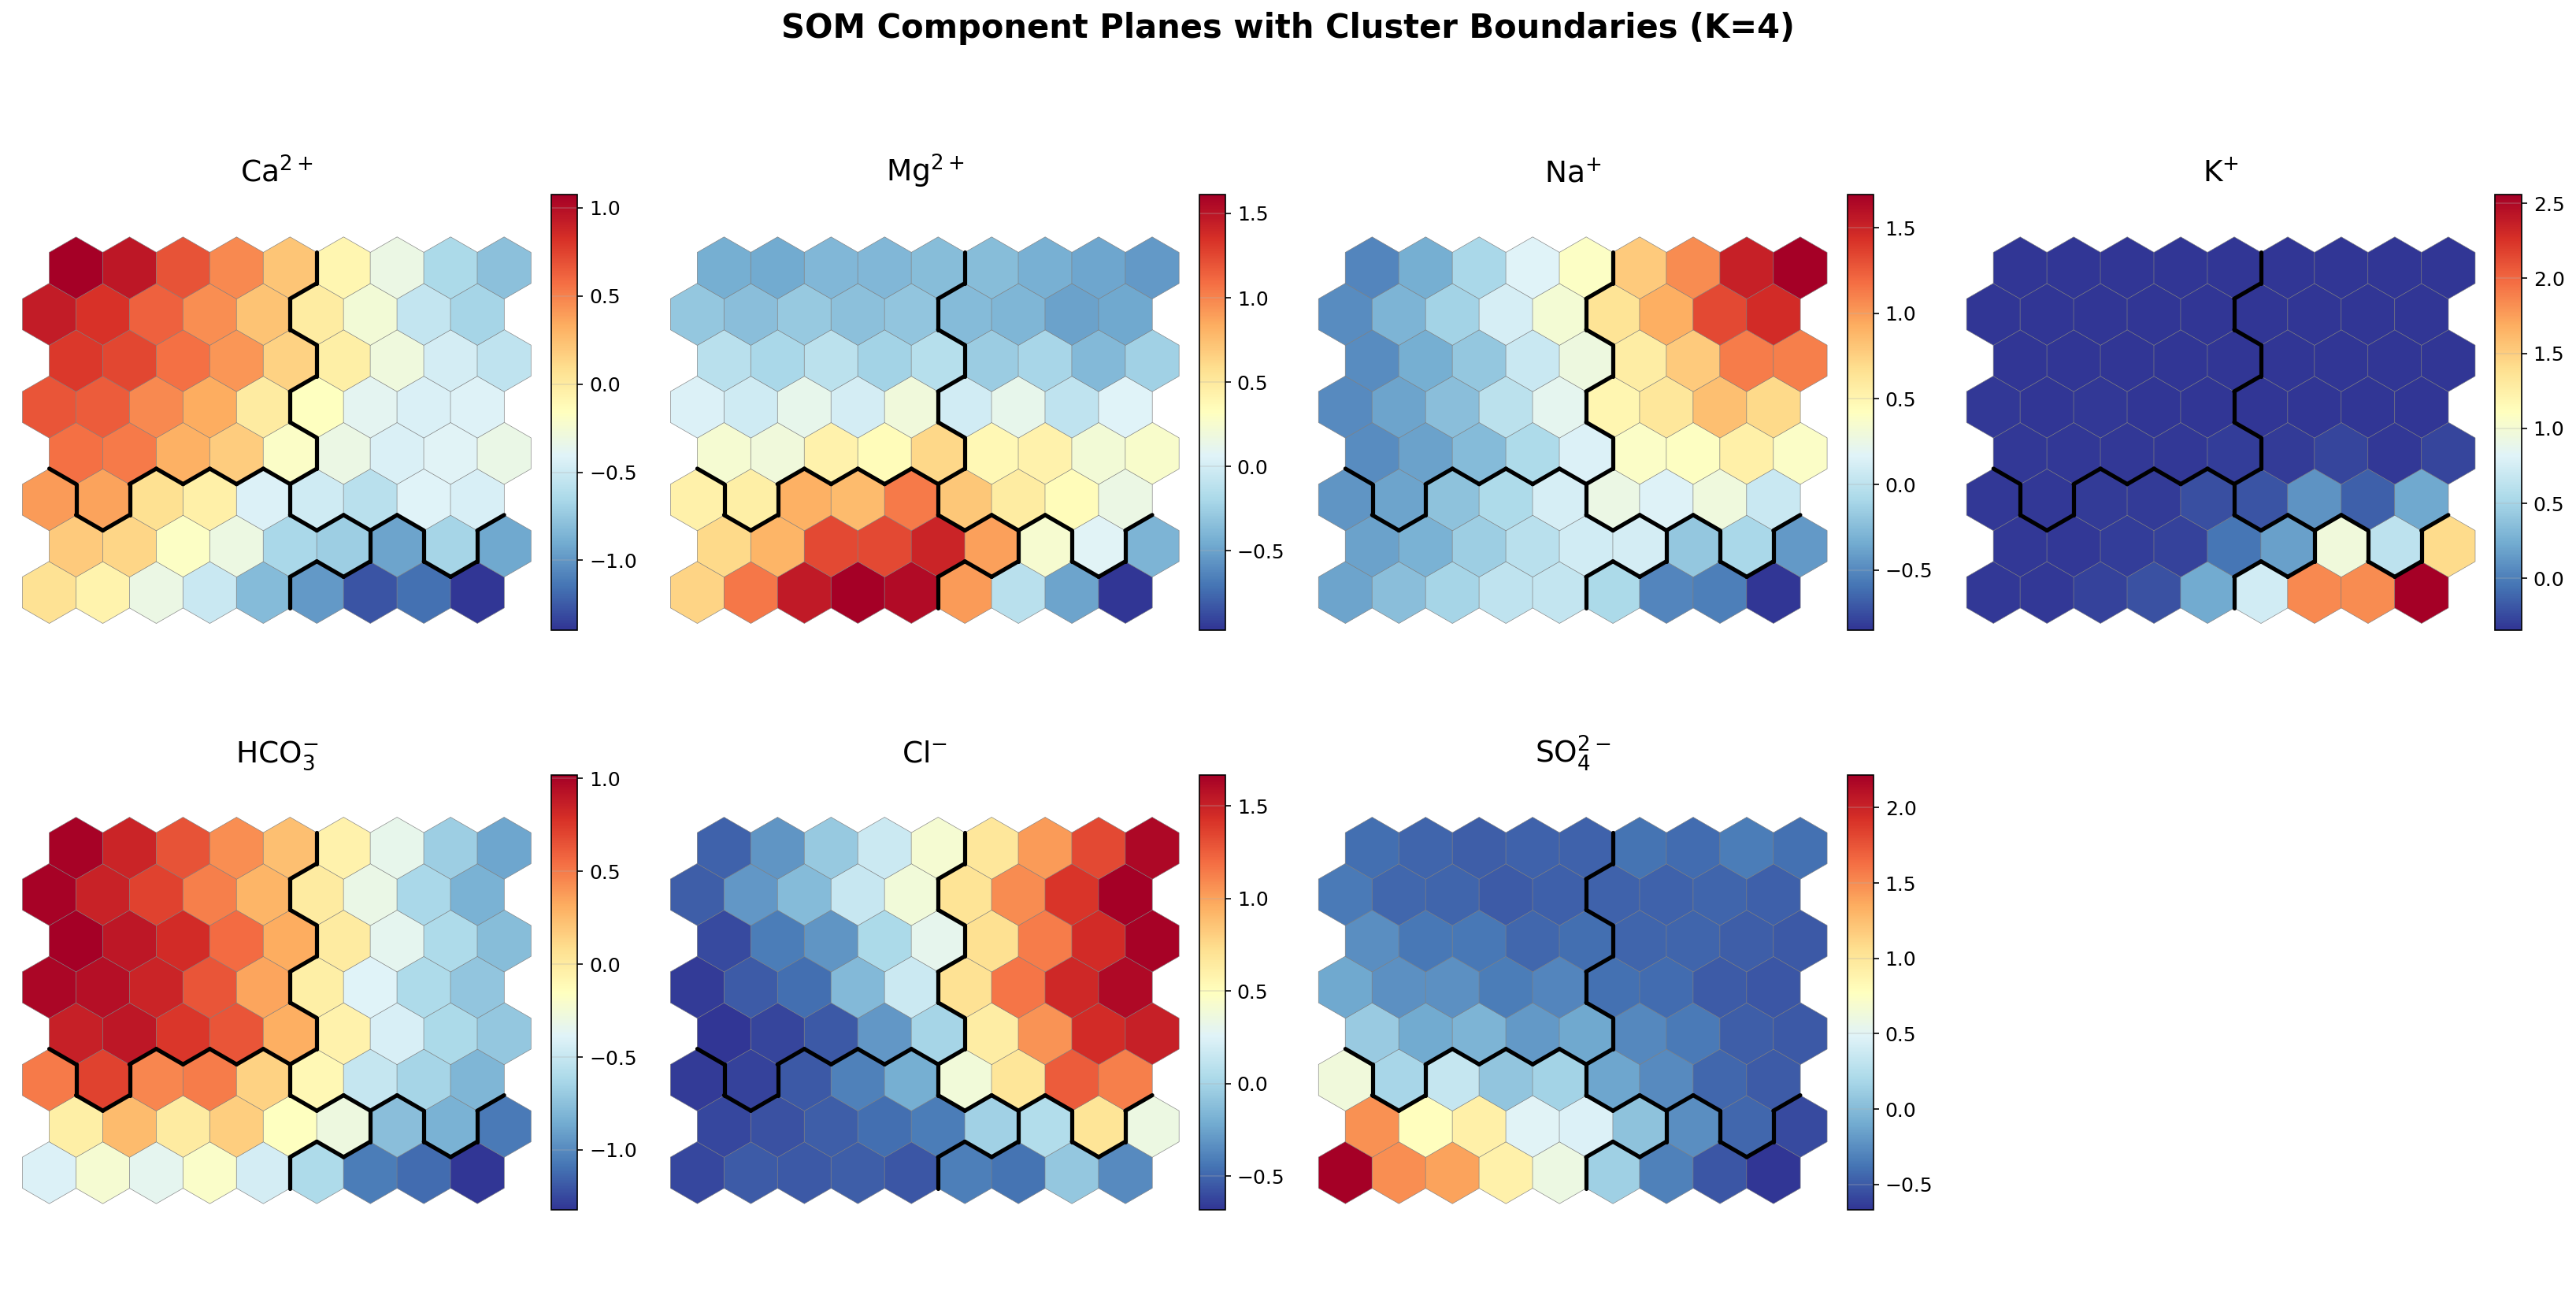

In [7]:
# ── Component planes with cluster boundaries drawn on the shared hex edges ─

# LaTeX labels
tex_labels = {
    "Ca":   r"$\mathrm{Ca^{2+}}$",
    "Mg":   r"$\mathrm{Mg^{2+}}$",
    "Na":   r"$\mathrm{Na^{+}}$",
    "K":    r"$\mathrm{K^{+}}$",
    "HCO3": r"$\mathrm{HCO_{3}^{-}}$",
    "Cl":   r"$\mathrm{Cl^{-}}$",
    "SO4":  r"$\mathrm{SO_{4}^{2-}}$",
}

def hex_neighbors(r, c, rows, cols):
    """Get valid hex neighbors for position (r, c)."""
    if r % 2 == 0:  # even row
        candidates = [(r-1,c-1),(r-1,c),(r,c-1),(r,c+1),(r+1,c-1),(r+1,c)]
    else:            # odd row
        candidates = [(r-1,c),(r-1,c+1),(r,c-1),(r,c+1),(r+1,c),(r+1,c+1)]
    return [(nr,nc) for nr,nc in candidates if 0<=nr<rows and 0<=nc<cols]


def get_hex_vertices(x, y, radius=0.58):
    """Return the 6 vertices of a flat-top hexagon centered at (x, y)."""
    angles = [np.pi/6 + i * np.pi/3 for i in range(6)]
    return [(x + radius * np.cos(a), y + radius * np.sin(a)) for a in angles]

def get_shared_edge(r1, c1, r2, c2, radius=0.58):
    """Find the two vertices shared between adjacent hexagons."""
    x1 = c1 + 0.5 * (r1 % 2)
    y1 = r1 * np.sqrt(3) / 2
    x2 = c2 + 0.5 * (r2 % 2)
    y2 = r2 * np.sqrt(3) / 2

    v1 = get_hex_vertices(x1, y1, radius)
    v2 = get_hex_vertices(x2, y2, radius)

    # Find vertices that are approximately the same (shared edge)
    shared = []
    for p1 in v1:
        for p2 in v2:
            if np.sqrt((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2) < 0.01:
                shared.append(p1)
    return shared

def plot_hex_plane_v2(weights, feature_idx, ion_label, ax,
                      neuron_cluster_map, cmap="RdYlBu_r"):
    """Component plane with clean edge-based cluster boundaries."""
    rows, cols, _ = weights.shape
    values = weights[:, :, feature_idx]

    # Draw hexagons
    patches = []
    colors_list = []
    for r in range(rows):
        for c in range(cols):
            x = c + 0.5 * (r % 2)
            y = r * np.sqrt(3) / 2
            hex_patch = RegularPolygon(
                (x, y), numVertices=6, radius=0.58,
                orientation=0, linewidth=0.3, edgecolor="gray"
            )
            patches.append(hex_patch)
            colors_list.append(values[r, c])

    pc = PatchCollection(patches, cmap=cmap, edgecolors="gray", linewidths=0.3)
    pc.set_array(np.array(colors_list))
    pc.set_clim(values.min(), values.max())
    ax.add_collection(pc)

    # Draw cluster boundary edges
    drawn_edges = set()
    for r in range(rows):
        for c in range(cols):
            my_cluster = neuron_cluster_map[r, c]
            for nr, nc in hex_neighbors(r, c, rows, cols):
                if neuron_cluster_map[nr, nc] != my_cluster:
                    edge_key = tuple(sorted([(r,c),(nr,nc)]))
                    if edge_key not in drawn_edges:
                        drawn_edges.add(edge_key)
                        shared = get_shared_edge(r, c, nr, nc)
                        if len(shared) == 2:
                            ax.plot([shared[0][0], shared[1][0]],
                                    [shared[0][1], shared[1][1]],
                                    color="black", linewidth=2.5,
                                    solid_capstyle="round", zorder=10)

    ax.set_xlim(-0.7, cols + 0.2)
    ax.set_ylim(-0.7, rows * np.sqrt(3) / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_title(tex_labels[ion_label], fontsize=18, fontweight="bold", pad=8)
    ax.axis("off")

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    cbar = plt.colorbar(pc, cax=cax)
    cbar.ax.tick_params(labelsize=12)

# ── Composite plot ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(22, 11))

for idx, ion in enumerate(ION_LABELS):
    row = idx // 4
    col = idx % 4
    plot_hex_plane_v2(weights, idx, ion, axes[row, col], neuron_cluster_map)

axes[1, 3].axis("off")

plt.suptitle(f"SOM Component Planes with Cluster Boundaries (K={K_FINAL})",
             fontsize=20, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM07_SOM_component_planes_K4_boundaries.png", dpi=800)
plt.show()

### <font color='orange'> **7) Export the dataset with clusters** </font>

In [8]:
# ── Export the dataset with BMU and Cluster columns ─────────────────

# Final dataframe has: metadata + mg/L + meq/L + % + scaled + BMU + Cluster
print("── Final dataframe columns ────────────────────────────────\n")
print(f"  Total columns : {len(df.columns)}")
print(f"  Total samples : {len(df)}")
print(f"  Cluster column: {'Cluster' in df.columns}")

# ── Export full dataset with Cluster ─────────────────────────────────
out_path = DIR_INTERMED / "data_final_with_clusters.xlsx"
df.to_excel(out_path, index=False, sheet_name="SOM_Clusters")
print(f"\nSaved: {out_path.relative_to(ROOT)}")

# ── Summary per cluster ─────────────────────────────────────────────
print(f"\n── Cluster summary ────────────────────────────────────────\n")
for k in range(1, K_FINAL + 1):
    df_ck = df[df["Cluster"] == k]
    types = df_ck["Type"].value_counts().to_dict()
    types_str = ", ".join([f"{t}({n})" for t, n in types.items()])
    print(f"  Cluster {k}: {len(df_ck):3d} samples - {types_str}")

# ── Check against the article ────────────────────────────────────────
counts = df["Cluster"].value_counts().to_dict()
assert counts == {1: 41, 2: 128, 3: 162, 4: 75}, counts
assert round(sil_k, 3) == 0.472
print("\n✓ Matches the article: C1 = 41, C2 = 128, C3 = 162, C4 = 75 samples; silhouette 0.472 for K = 4.")

── Final dataframe columns ────────────────────────────────

  Total columns : 38
  Total samples : 406
  Cluster column: True

Saved: outputs\intermediate\data_final_with_clusters.xlsx

── Cluster summary ────────────────────────────────────────

  Cluster 1:  41 samples - Groundwater(41)
  Cluster 2: 128 samples - Groundwater(121), Stream(5), Lac(1), Tributary(1)
  Cluster 3: 162 samples - Groundwater(94), Stream(31), Spring(29), Snow(3), Rain(2), Irrigation(2), Tributary(1)
  Cluster 4:  75 samples - Groundwater(49), Spring(20), Stream(4), Dam(2)

✓ Matches the article: C1 = 41, C2 = 128, C3 = 162, C4 = 75 samples; silhouette 0.472 for K = 4.


### <font color='orange'> **8) Agreement between the SOM-based facies and a direct clustering of the samples (Table SM3)** </font>

The four facies result from the hierarchical clustering of the 72 SOM prototypes (two-level clustering). A direct hierarchical clustering of the 406 samples with the same seven standardized variables and Euclidean distance (Ward linkage, K = 4, the dendrogram of Figure 7) is compared with the SOM-based facies by a contingency table, the adjusted Rand index (ARI; 1 = identical partitions, 0 = chance) and the share of samples in the matching group after optimal label pairing. Average linkage, the one used on the prototypes, is given as a second reference. Both partitions use the same variables and distance, so the agreement is a consistency check, not an independent confirmation.

In [9]:
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

som_lab = df["Cluster"].values
out_rows, tables = [], {}
for method in ("ward", "average"):   # Ward = the Figure 7 dendrogram; average = the linkage used on the prototypes
    Zs = linkage(data_som, method=method, metric="euclidean")
    direct = fcluster(Zs, t=K_FINAL, criterion="maxclust")
    ct = pd.crosstab(pd.Series(som_lab, name="SOM-based cluster"), pd.Series(direct, name=f"direct HCA ({method})"))
    r, c = linear_sum_assignment(-ct.values)                     # pair the labels that overlap most
    matched = ct.values[r, c].sum()
    ari = adjusted_rand_score(som_lab, direct)
    tables[method] = ct
    out_rows.append({"linkage": method, "ARI": round(ari, 3), "samples in matching cluster": int(matched),
                     "percent": round(100 * matched / len(df), 1)})
    print(f"Direct HCA on the 406 samples, {method} linkage, K = {K_FINAL}: ARI = {ari:.3f}, "
          f"{matched} of {len(df)} samples ({100 * matched / len(df):.1f} %) in the matching cluster")
    display(ct)
summary8 = pd.DataFrame(out_rows)
with pd.ExcelWriter(DIR_TABLES / "som_vs_direct_hca_agreement.xlsx", engine="openpyxl") as w:
    summary8.to_excel(w, sheet_name="summary", index=False)
    for method, ct in tables.items():
        ct.to_excel(w, sheet_name=f"contingency_{method}")
print("Saved: outputs/tables/som_vs_direct_hca_agreement.xlsx")

# ── Check against the article (Section 3.4, Table SM3) ───────────────
assert summary8.loc[0, "linkage"] == "ward" and round(summary8.loc[0, "ARI"], 2) == 0.65 and summary8.loc[0, "samples in matching cluster"] == 343
print("✓ Matches the article: Ward linkage, 343 of 406 samples (84.5 %), adjusted Rand index 0.65.")

Direct HCA on the 406 samples, ward linkage, K = 4: ARI = 0.651, 343 of 406 samples (84.5 %) in the matching cluster


direct HCA (ward),1,2,3,4
SOM-based cluster,,,,
1,0,0,41,0
2,0,4,0,124
3,0,153,0,9
4,25,38,0,12


Direct HCA on the 406 samples, average linkage, K = 4: ARI = 0.179, 204 of 406 samples (50.2 %) in the matching cluster


direct HCA (average),1,2,3,4
SOM-based cluster,,,,
1,41,0,0,0
2,0,128,0,0
3,0,162,0,0
4,0,73,1,1


Saved: outputs/tables/som_vs_direct_hca_agreement.xlsx
✓ Matches the article: Ward linkage, 343 of 406 samples (84.5 %), adjusted Rand index 0.65.


---
**Figures:** SM7, SM8, SM9 in `outputs/figures/`

**Outputs:** `outputs/intermediate/data_final_with_clusters.xlsx`; `outputs/tables/som_vs_direct_hca_agreement.xlsx` (Table SM3)

**Next:** `03_SOM_figures.ipynb` (clustered SOM map, HCA dendrogram with Stiff diagrams, Piper and Gibbs diagrams: Figures 6, 7, 8, 9)